# 03 - Exploratory Data Analysis
Figures that only need the cleaned cubes and the location summaries.

**Reads:** `processed/madrid_px.parquet`, `processed/amsterdam_px.parquet`, `processed/*_cube2.pkl`
**Next:** `04_feature_engineering_and_modelling.ipynb`

Figures 4, 5, 7 and 11 describe *engineered features*, so they live in notebook 04 right after the features are built (features cannot exist before EDA in this order).

## 1. Setup and plot style

In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

OUT_DIR = "processed"

# Age classes are ORDERED, so they get an ordinal ramp (light = older),
# not four arbitrary colours. Cities get two distinct hues.
CLASS_C = ["#86b6ef", "#3987e5", "#256abf", "#104281"]
CITY_C  = {"Madrid": "#2a78d6", "Amsterdam": "#eb6834"}
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURF = "#e1e0d9", "#c3c2b7", "#fcfcfb"

BOUNDS = {"Madrid": [1960, 1984, 2004], "Amsterdam": [1945, 1984, 2004]}
YEARS  = np.arange(1984, 2026)

plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": GRID, "grid.linewidth": 0.7,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
})
print("plot style ready")

plot style ready


## 2. Load the cleaned data

In [2]:
madrid_px = pd.read_parquet(f"{OUT_DIR}/madrid_px.parquet")
amsterdam_px = pd.read_parquet(f"{OUT_DIR}/amsterdam_px.parquet")
madrid_cube2 = pd.read_pickle(f"{OUT_DIR}/madrid_cube2.pkl")
amsterdam_cube2 = pd.read_pickle(f"{OUT_DIR}/amsterdam_cube2.pkl")
print("madrid   ", madrid_px.shape, madrid_cube2["NIR"].shape)
print("amsterdam", amsterdam_px.shape, amsterdam_cube2["NIR"].shape)

madrid    (76263, 4) (76263, 42)
amsterdam (25992, 4) (25992, 42)


## Figure 1 - Why the challenge is hard
The class boundaries differ between cities.

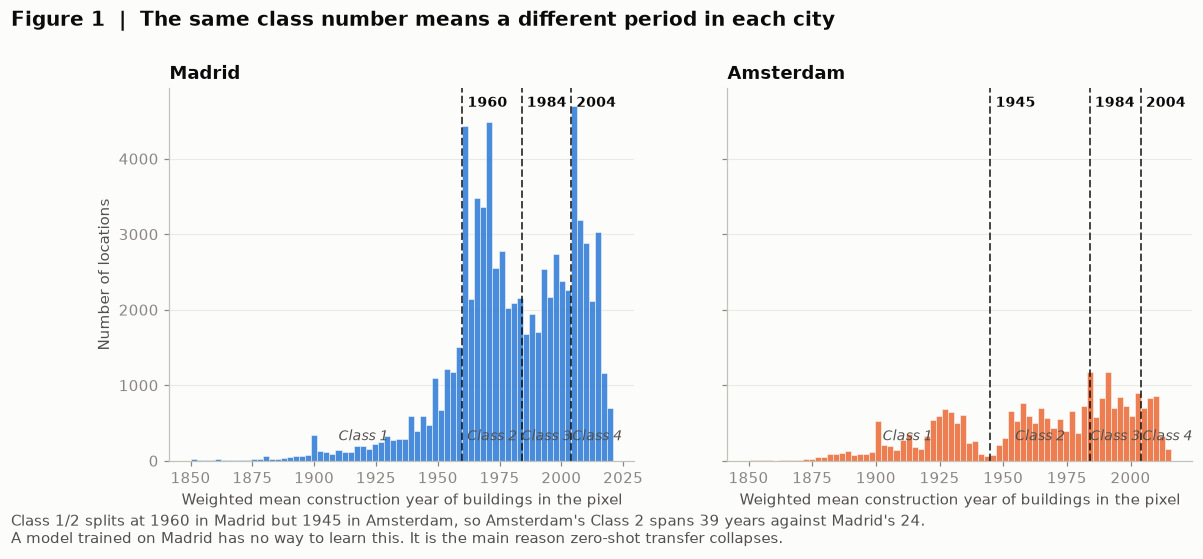

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)

for ax, px, city in zip(axes, [madrid_px, amsterdam_px], ["Madrid", "Amsterdam"]):
    yr = px["weighted_mean_year"].clip(1850, 2025)
    ax.hist(yr, bins=70, color=CITY_C[city], alpha=0.85,
            edgecolor=SURF, linewidth=0.4)
    top = ax.get_ylim()[1]
    for b in BOUNDS[city]:
        ax.axvline(b, color=INK, lw=1.3, ls="--", alpha=0.75)
        ax.text(b + 2, top * 0.95, str(b), fontsize=9, color=INK, fontweight="bold")
    # label the four class regions
    edges = [1850] + BOUNDS[city] + [2025]
    for i in range(4):
        mid = (max(edges[i], 1880) + edges[i + 1]) / 2
        ax.text(mid, top * 0.055, f"Class {i+1}", fontsize=9, color=INK2,
                ha="center", style="italic")
    ax.set_title(city, loc="left")
    ax.set_xlabel("Weighted mean construction year of buildings in the pixel")
    ax.grid(axis="y", alpha=0.6); ax.set_axisbelow(True)

axes[0].set_ylabel("Number of locations")
fig.suptitle("Figure 1  |  The same class number means a different period in each city",
             x=0.005, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.text(0.005, -0.06,
         "Class 1/2 splits at 1960 in Madrid but 1945 in Amsterdam, so Amsterdam's "
         "Class 2 spans 39 years against Madrid's 24.\nA model trained on Madrid has no "
         "way to learn this. It is the main reason zero-shot transfer collapses.",
         fontsize=9.5, color=INK2, ha="left")
plt.show()

## Figure 2 - Class balance

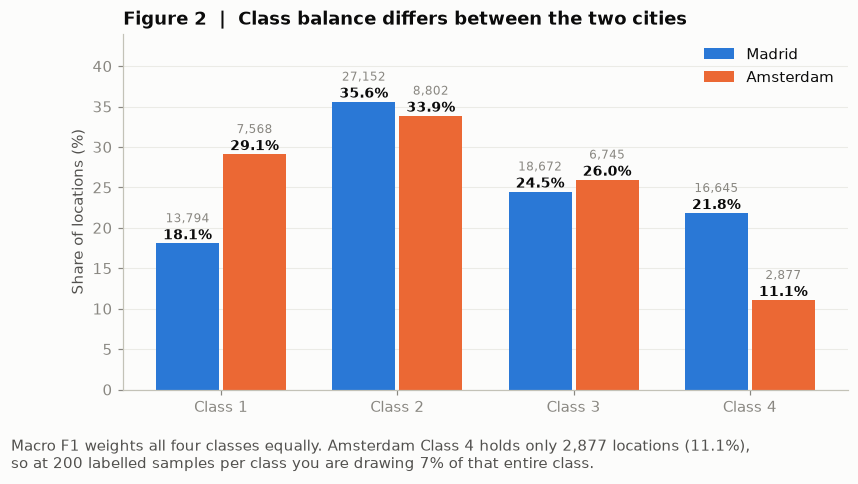

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
w, x = 0.38, np.arange(4)

for i, (px, city) in enumerate([(madrid_px, "Madrid"), (amsterdam_px, "Amsterdam")]):
    counts = px["age_class"].value_counts().sort_index()
    pct = counts / counts.sum() * 100
    bars = ax.bar(x + (i - 0.5) * w, pct.values, w * 0.94,
                  label=city, color=CITY_C[city])
    for b, p, n in zip(bars, pct.values, counts.values):
        ax.text(b.get_x() + b.get_width()/2, p + 0.5, f"{p:.1f}%",
                ha="center", fontsize=9, color=INK, fontweight="bold")
        ax.text(b.get_x() + b.get_width()/2, p + 2.6, f"{n:,}",
                ha="center", fontsize=8, color=MUTED)

ax.set_xticks(x, [f"Class {i+1}" for i in range(4)])
ax.set_ylabel("Share of locations (%)")
ax.set_ylim(0, 44)
ax.set_title("Figure 2  |  Class balance differs between the two cities", loc="left")
ax.grid(axis="y", alpha=0.6); ax.set_axisbelow(True)
ax.legend(loc="upper right")
fig.text(0.005, -0.06,
         "Macro F1 weights all four classes equally. Amsterdam Class 4 holds only "
         "2,877 locations (11.1%),\nso at 200 labelled samples per class you are drawing "
         "7% of that entire class.",
         fontsize=9.5, color=INK2, ha="left")
plt.show()

## Figure 3 - The age signal over time

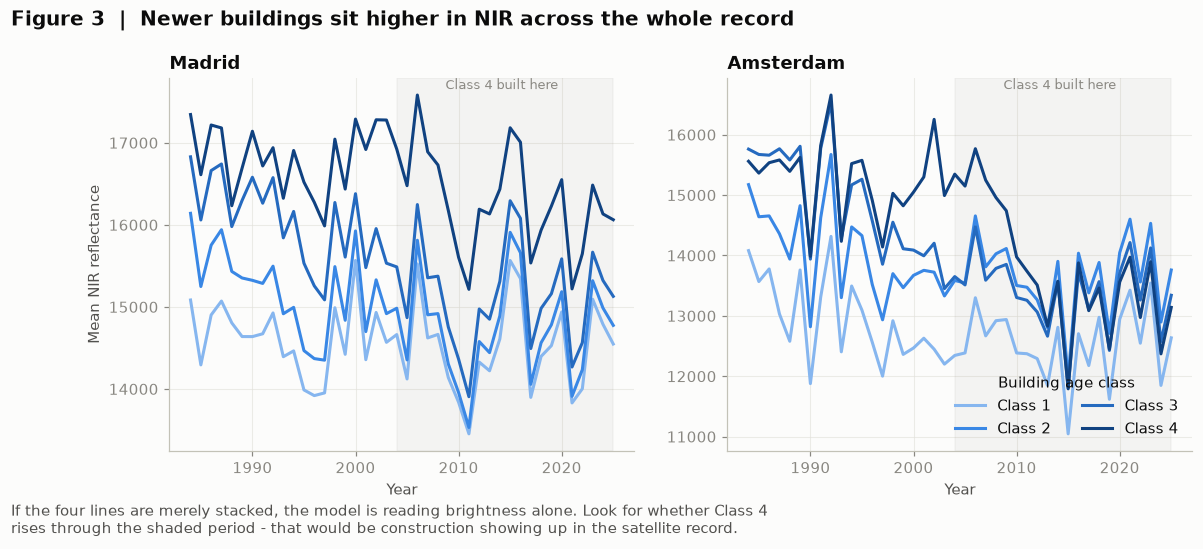

In [5]:
BAND = "NIR"          # try "SWIR1" too
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

for ax, cube, px, city in zip(axes, [madrid_cube2, amsterdam_cube2],
                              [madrid_px, amsterdam_px], ["Madrid", "Amsterdam"]):
    p = cube[BAND]
    lab = px["age_class"].reindex(p.index)
    for c in (1, 2, 3, 4):
        ax.plot(YEARS, p[lab == c].mean().values, lw=2,
                color=CLASS_C[c-1], label=f"Class {c}")
    ax.axvspan(2004, 2025, color=MUTED, alpha=0.07)
    ax.text(2014, ax.get_ylim()[1], " Class 4 built here", fontsize=8.5,
            color=MUTED, va="top", ha="center")
    ax.set_title(city, loc="left")
    ax.set_xlabel("Year")
    ax.grid(alpha=0.6); ax.set_axisbelow(True)

axes[0].set_ylabel(f"Mean {BAND} reflectance")
axes[1].legend(loc="lower right", ncol=2, title="Building age class")
fig.suptitle(f"Figure 3  |  Newer buildings sit higher in {BAND} across the whole record",
             x=0.005, ha="left", fontsize=13, fontweight="bold", y=1.02)
fig.text(0.005, -0.06,
         "If the four lines are merely stacked, the model is reading brightness alone. "
         "Look for whether Class 4\nrises through the shaded period - that would be "
         "construction showing up in the satellite record.",
         fontsize=9.5, color=INK2, ha="left")
plt.show()

## Figure 6 - Cleaning effect
(Before/after numbers are the values recorded from notebook 02's diagnostics.)

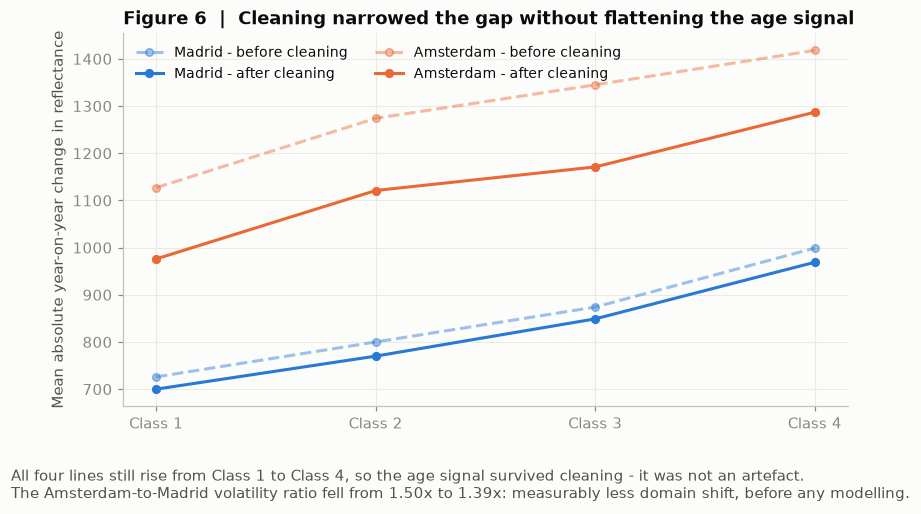

In [6]:
before_m, after_m = [726, 800, 874, 999], [700, 770, 849, 969]
before_a, after_a = [1127, 1274, 1345, 1418], [976, 1121, 1171, 1287]

fig, ax = plt.subplots(figsize=(8.5, 4.4))
x = np.arange(4)
for vals, city, ls, alpha, lab in [
    (before_m, "Madrid", "--", 0.45, "Madrid - before cleaning"),
    (after_m,  "Madrid", "-",  1.0,  "Madrid - after cleaning"),
    (before_a, "Amsterdam", "--", 0.45, "Amsterdam - before cleaning"),
    (after_a,  "Amsterdam", "-",  1.0,  "Amsterdam - after cleaning"),
]:
    ax.plot(x, vals, ls, lw=2, color=CITY_C[city], label=lab,
            marker="o", ms=5, alpha=alpha)

ax.set_xticks(x, [f"Class {i+1}" for i in range(4)])
ax.set_ylabel("Mean absolute year-on-year change in reflectance")
ax.set_title("Figure 6  |  Cleaning narrowed the gap without flattening the age signal",
             loc="left")
ax.grid(alpha=0.6); ax.set_axisbelow(True)
ax.legend(ncol=2, loc="upper left", fontsize=9)
fig.text(0.005, -0.08,
         "All four lines still rise from Class 1 to Class 4, so the age signal survived "
         "cleaning - it was not an artefact.\nThe Amsterdam-to-Madrid volatility ratio fell "
         "from 1.50x to 1.39x: measurably less domain shift, before any modelling.",
         fontsize=9.5, color=INK2, ha="left")
plt.show()

## Figure 8 - Single-pixel trajectories
Every plot so far is a class average, which smears a sharp construction event into a gentle slope. This plots individual locations.

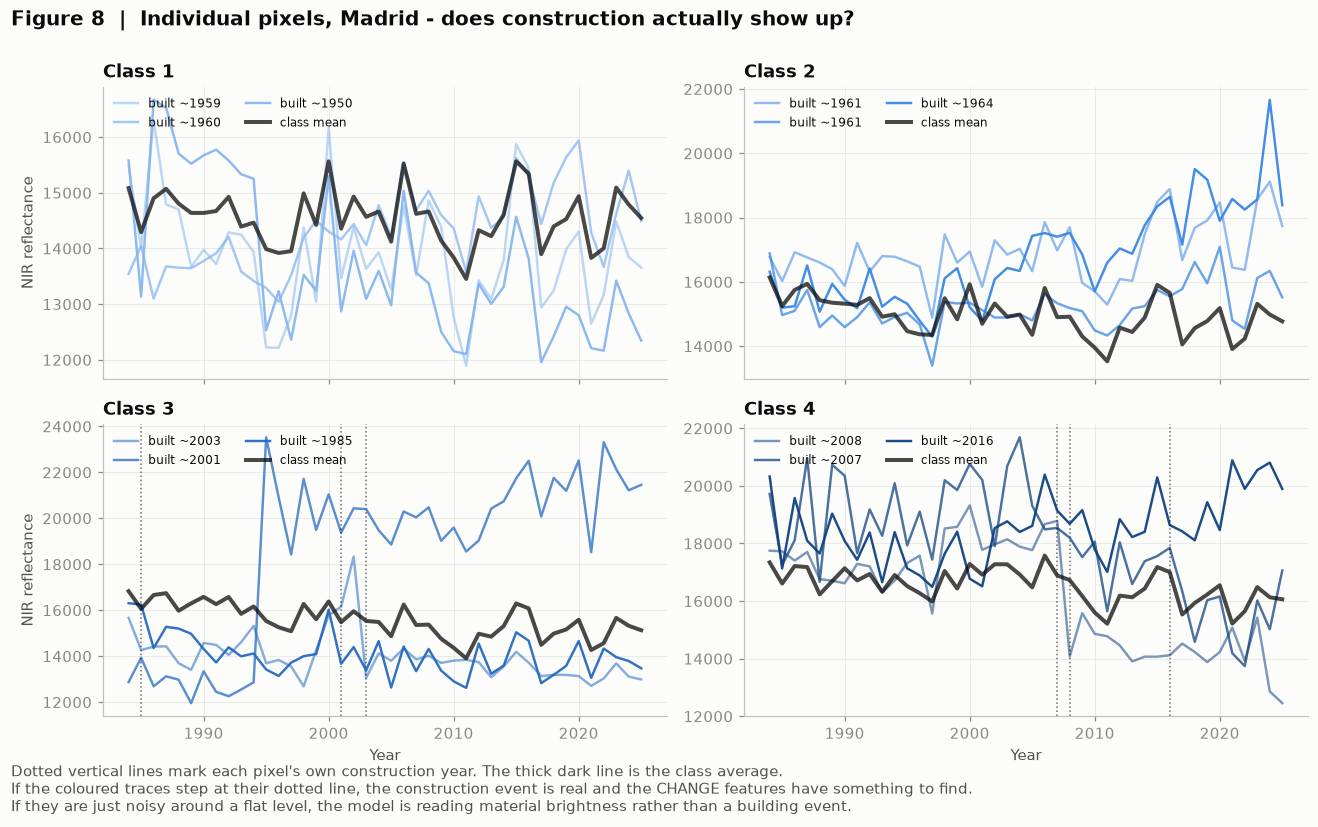

In [7]:
BAND = "NIR"
N_PER_CLASS = 3
rng = np.random.default_rng(42)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)

p = madrid_cube2[BAND]
lab = madrid_px["age_class"].reindex(p.index)
yr = madrid_px["weighted_mean_year"].reindex(p.index)
# Prefer well-covered pixels: a clearer signal, not a cherry-picked one
cov = madrid_px["coverage"].reindex(p.index)

for c, ax in zip((1, 2, 3, 4), axes.ravel()):
    pool = np.where((lab == c).to_numpy() & (cov > 0.6).to_numpy())[0]
    pick = rng.choice(pool, size=min(N_PER_CLASS, len(pool)), replace=False)
    for k, i in enumerate(pick):
        ax.plot(YEARS, p.iloc[i].values, lw=1.6, color=CLASS_C[c-1],
                alpha=0.55 + 0.2*k,
                label=f"built ~{yr.iloc[i]:.0f}")
        # mark that pixel's own construction year if inside the record
        if 1984 < yr.iloc[i] < 2025:
            ax.axvline(yr.iloc[i], color=INK, lw=1.0, ls=":", alpha=0.6)
    ax.plot(YEARS, p[lab == c].mean().values, lw=2.6, color=INK, alpha=0.75,
            label="class mean")
    ax.set_title(f"Class {c}", loc="left")
    ax.grid(alpha=0.6); ax.set_axisbelow(True)
    ax.legend(fontsize=8, loc="upper left", ncol=2)

for ax in axes[1]:
    ax.set_xlabel("Year")
for ax in axes[:, 0]:
    ax.set_ylabel(f"{BAND} reflectance")

fig.suptitle("Figure 8  |  Individual pixels, Madrid - does construction actually show up?",
             x=0.005, ha="left", fontsize=13, fontweight="bold", y=1.00)
fig.text(0.005, -0.04,
         "Dotted vertical lines mark each pixel's own construction year. The thick dark "
         "line is the class average.\nIf the coloured traces step at their dotted line, "
         "the construction event is real and the CHANGE features have something to find.\n"
         "If they are just noisy around a flat level, the model is reading material "
         "brightness rather than a building event.",
         fontsize=9.5, color=INK2, ha="left")
plt.tight_layout()
plt.show()

## Figure 9 - Building coverage distribution
Coverage is the one non-spectral feature. It differs systematically between the cities, so look before trusting.

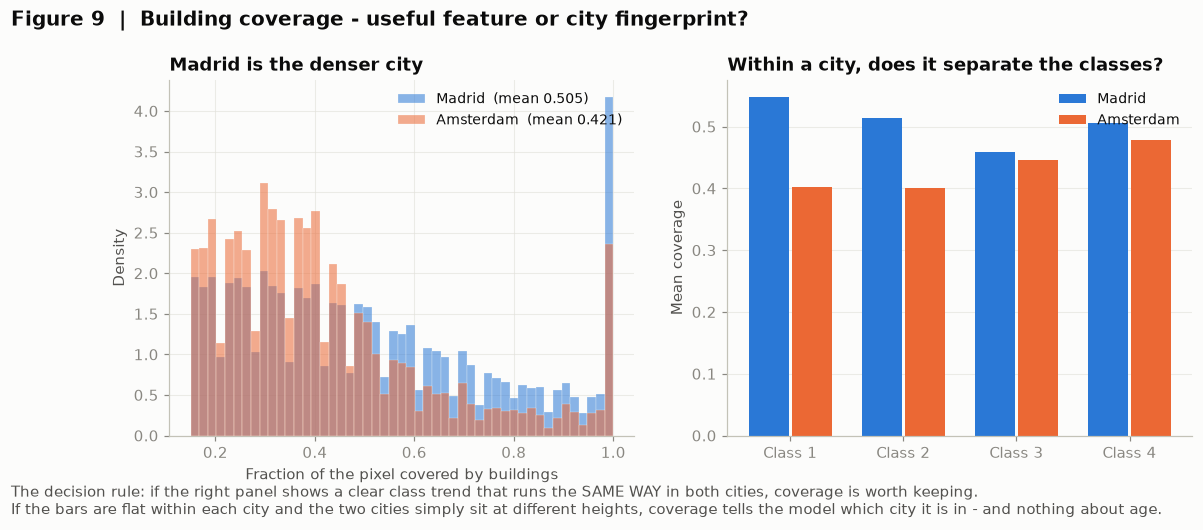

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# left: overall distribution per city
ax = axes[0]
bins = np.linspace(0.15, 1.0, 50)
for px, city in [(madrid_px, "Madrid"), (amsterdam_px, "Amsterdam")]:
    ax.hist(px["coverage"], bins=bins, density=True, alpha=0.55,
            color=CITY_C[city], label=f"{city}  (mean {px['coverage'].mean():.3f})",
            edgecolor=SURF, linewidth=0.3)
ax.set_xlabel("Fraction of the pixel covered by buildings")
ax.set_ylabel("Density")
ax.set_title("Madrid is the denser city", loc="left")
ax.legend(loc="upper right", fontsize=9)
ax.grid(alpha=0.6); ax.set_axisbelow(True)

# right: does coverage carry age information, or just city identity?
ax = axes[1]
w, x = 0.38, np.arange(4)
for i, (px, city) in enumerate([(madrid_px, "Madrid"), (amsterdam_px, "Amsterdam")]):
    means = px.groupby("age_class")["coverage"].mean()
    ax.bar(x + (i - 0.5)*w, means.values, w*0.94, color=CITY_C[city], label=city)
ax.set_xticks(x, [f"Class {i+1}" for i in range(4)])
ax.set_ylabel("Mean coverage")
ax.set_title("Within a city, does it separate the classes?", loc="left")
ax.legend(loc="upper right", fontsize=9)
ax.grid(axis="y", alpha=0.6); ax.set_axisbelow(True)

fig.suptitle("Figure 9  |  Building coverage - useful feature or city fingerprint?",
             x=0.005, ha="left", fontsize=13, fontweight="bold", y=1.03)
fig.text(0.005, -0.06,
         "The decision rule: if the right panel shows a clear class trend that runs the "
         "SAME WAY in both cities, coverage is worth keeping.\nIf the bars are flat within "
         "each city and the two cities simply sit at different heights, coverage tells the "
         "model which city it is in - and nothing about age.",
         fontsize=9.5, color=INK2, ha="left")
plt.show()

## Figure 10 - How much temporal signal each class carries
Distribution, not just the mean.

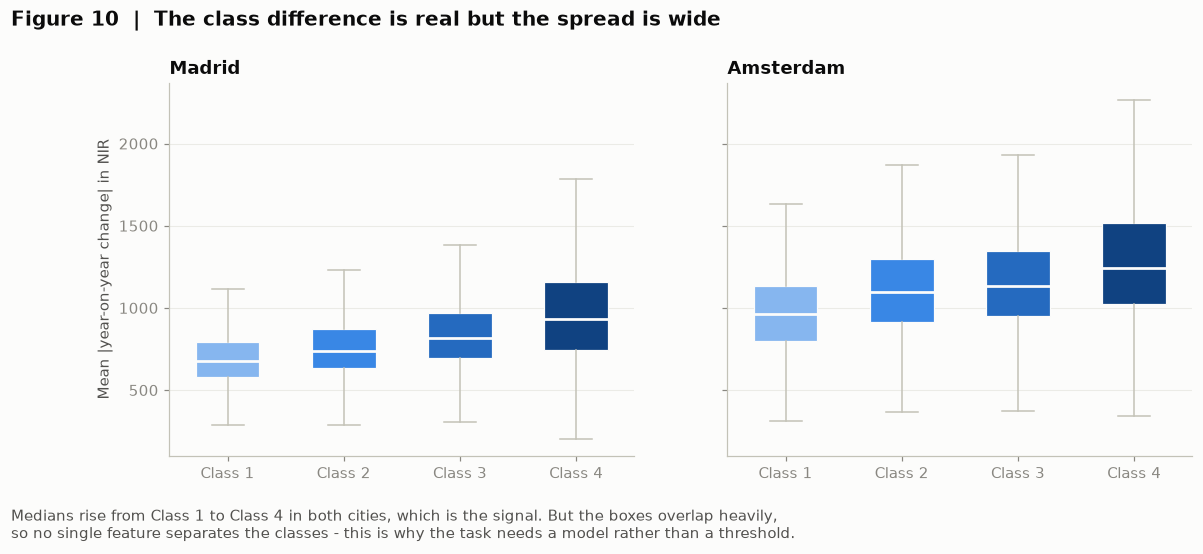

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)

for ax, cube, px, city in zip(axes, [madrid_cube2, amsterdam_cube2],
                              [madrid_px, amsterdam_px], ["Madrid", "Amsterdam"]):
    p = cube["NIR"]
    lab = px["age_class"].reindex(p.index)
    vol = p.diff(axis=1).abs().mean(axis=1)
    data = [vol[lab == c].dropna().values for c in (1, 2, 3, 4)]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.55,
                    medianprops=dict(color=SURF, lw=1.8),
                    whiskerprops=dict(color=AXIS), capprops=dict(color=AXIS),
                    boxprops=dict(edgecolor=SURF, linewidth=0.8))
    for patch, col in zip(bp["boxes"], CLASS_C):
        patch.set_facecolor(col)
    ax.set_xticklabels([f"Class {i+1}" for i in range(4)])
    ax.set_title(city, loc="left")
    ax.grid(axis="y", alpha=0.6); ax.set_axisbelow(True)

axes[0].set_ylabel("Mean |year-on-year change| in NIR")
fig.suptitle("Figure 10  |  The class difference is real but the spread is wide",
             x=0.005, ha="left", fontsize=13, fontweight="bold", y=1.03)
fig.text(0.005, -0.06,
         "Medians rise from Class 1 to Class 4 in both cities, which is the signal. But the "
         "boxes overlap heavily,\nso no single feature separates the classes - this is why "
         "the task needs a model rather than a threshold.",
         fontsize=9.5, color=INK2, ha="left")
plt.show()